# 07 · Model explanations with SHAP

**Purpose.** Complement the permutation importance of notebooks 05 and 06 with **SHAP values** for the winning models: the model with the best point estimate and every model that the paired bootstrap could not distinguish from it.

**What a SHAP value is** (`src/explain.py`). For one patient, the prediction is split into one contribution per input:

prediction = base value (average prediction) + sum of the contributions of all inputs.

Each contribution is the **Shapley value** of a cooperative game whose players are the inputs: the average change in the prediction when that input is added to every possible subset of the others. Contributions are additive and sum exactly to the prediction (checked below).
- Random forest and pruned tree: exact **TreeSHAP**, in **probability** units.
- XGBoost: exact TreeSHAP, in **log-odds** units (its raw output).
- Logistic regression: closed form, coefficient × (value − mean value), in **log-odds** units.

Because the units differ, models are compared by the **ranking** and the **share** of mean |SHAP|, not by the raw values.

**How it differs from permutation importance.** Permutation importance is computed on held-out folds and measures how much the *performance* drops without an input. SHAP is computed on the final model (fitted on all patients) and describes how the model *uses* each input, patient by patient, including the direction of the effect. Neither measures a causal effect (notebook 08).

| # | Section |
|---|---|
| 1 | Setup and winning models |
| 2 | Binary task: SHAP values and additivity |
| 3 | Binary task: global importance vs permutation importance |
| 4 | Binary task: summary plots |
| 5 | Binary task: the effect of age |
| 6 | Multiclass task: what distinguishes each family |
| 7 | Summary |

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Project root (folder containing src/config.py) not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import display

from src import config, data, evaluation as ev, explain, models, plotting, reporting
from src.plotting import NEUTRAL

plotting.set_style()
pd.set_option("display.precision", 3)

df = data.load_processed()
FEATURES = data.feature_columns("classification")
X = df[FEATURES]
y_bin = df["Grade"].values
y_mc = data.diagnosis_family(df)
LABELS = [config.MULTICLASS_LABELS[k] for k in range(len(config.MULTICLASS_LABELS))]
R05 = json.loads((config.LOGS / "05_classification.json").read_text())
R06 = json.loads((config.LOGS / "06_multiclass.json").read_text())
EXPLAINABLE = {"Logistic regression", "Random forest", "XGBoost", "Decision tree (pruned)"}

def winners(best, paired, diff_key):
    # best model + models whose paired difference with it has a CI that includes 0
    tied = [r["Model"] for r in paired if r["CI high"] >= 0 and r["Model"] != best]
    return [m for m in [best] + tied if m in EXPLAINABLE]

def same_params(a, b):
    return set(a) == set(b) and all(np.isclose(a[k], b[k]) if isinstance(b[k], float) else a[k] == b[k] for k in b)

WIN_BIN = winners(R05["best_auc"], R05["paired_auc_differences"], "AUC")
WIN_MC = winners(R06["best"], R06["paired_differences"], "Macro AUC")
print("Binary winners:", WIN_BIN, "| multiclass winners:", WIN_MC)
results = {"winners_binary": WIN_BIN, "winners_multiclass": WIN_MC}

Binary winners: ['Random forest', 'Logistic regression', 'XGBoost'] | multiclass winners: ['Random forest', 'Logistic regression', 'XGBoost']


C:\Users\ori\anaconda3\envs\glioma-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Binary task: SHAP values and additivity

The final models are refitted with the same tuning procedure as in notebook 05 (deterministic: same seed, same folds), and the chosen hyperparameters are checked against those saved by notebook 05.

In [2]:
MB = models.classification_models(FEATURES)
SV_BIN, check = {}, []
for name in WIN_BIN:
    model, params = ev.fit_final(*MB[name], X, y_bin, "classification", ev.CLASSIFICATION_SCORING)
    saved = R05["final_hyperparameters"][name]
    assert same_params(params, saved), f"{name}: hyperparameters differ from notebook 05"
    SV_BIN[name] = explain.shap_values(model, X)
    check.append({"Model": name, "Hyperparameters": str(params), "Units": SV_BIN[name]["units"],
                  "Base value": SV_BIN[name]["base"], "Max additivity error": explain.additivity_error(SV_BIN[name])})
check = pd.DataFrame(check)
display(check)
results["binary_check"] = check.to_dict(orient="records")

,Model,Hyperparameters,Units,Base value,Max additivity error
0,Random forest,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",probability,0.422,1.284e-15
1,Logistic regression,"{'C': 100.0, 'penalty': 'l1'}",log-odds,-1.142,3.553e-15
2,XGBoost,"{'learning_rate': 0.03, 'max_depth': 5, 'n_est...",log-odds,-0.329,1.669e-06


## 3. Binary task: global importance vs permutation importance

Mean |SHAP| per input. The one-hot race columns are first added up per patient (the contribution of *race*), so that SHAP and permutation importance (which shuffles the original `Race` column) rank the same 23 predictors. Spearman's ρ measures the agreement of the two rankings.

In [3]:
def by_original_column(sv):
    vals = pd.DataFrame(sv["values"], columns=sv["inputs"].columns)
    race = [c for c in vals if c.startswith("Race")]
    vals["Race"] = vals[race].sum(axis=1)
    vals = vals.drop(columns=race)
    imp = vals.abs().mean()
    return (imp / imp.sum()).reindex(FEATURES)

perm = pd.DataFrame(R05["permutation_importance_mean"]).T.reindex(FEATURES)
share = pd.DataFrame({m: by_original_column(SV_BIN[m]) for m in WIN_BIN})
agree = []
for m in WIN_BIN:
    rho = spearmanr(share[m], perm[m]).statistic if m in perm else np.nan
    top_shap, top_perm = share[m].sort_values(ascending=False).index[:3].tolist(), perm[m].sort_values(ascending=False).index[:3].tolist() if m in perm else []
    agree.append({"Model": m, "Spearman rho (SHAP vs permutation)": rho, "Top 3 SHAP": ", ".join(top_shap), "Top 3 permutation": ", ".join(top_perm)})
agree = pd.DataFrame(agree)
display(agree)
order = share.mean(axis=1).sort_values(ascending=False).index
display(share.loc[order].head(10))
results["binary_shap_share"] = share.to_dict(orient="index")
results["binary_agreement"] = agree.to_dict(orient="records")
reporting.save_table_tex(share.loc[order].head(10).rename_axis("Predictor").reset_index(), "shap_binary_share", float_format="{:.3f}")
reporting.save_table_tex(agree, "shap_binary_agreement", float_format="{:.3f}", column_format="lrll")

,Model,Spearman rho (SHAP vs permutation),Top 3 SHAP,Top 3 permutation
0,Random forest,0.847,"IDH1, Age_at_diagnosis, PTEN","IDH1, Age_at_diagnosis, ATRX"
1,Logistic regression,0.789,"IDH1, NOTCH1, TP53","IDH1, NOTCH1, Age_at_diagnosis"
2,XGBoost,0.678,"IDH1, Age_at_diagnosis, TP53","IDH1, Age_at_diagnosis, TP53"


,Random forest,Logistic regression,XGBoost
IDH1,0.462,0.360,5.958e-01
Age_at_diagnosis,0.171,0.091,1.155e-01
TP53,0.017,0.091,1.063e-01
NOTCH1,0.010,0.138,0.000e+00
PTEN,0.086,0.030,2.424e-02
IDH2,0.021,0.048,4.027e-02
CIC,0.060,0.029,4.592e-04
ATRX,0.056,0.014,1.108e-02
EGFR,0.019,0.021,2.083e-02
NF1,0.011,0.024,2.582e-02


WindowsPath('C:/Users/ori/ML/results/tables/shap_binary_agreement.tex')

## 4. Binary task: summary plots

One row per input (the 10 with the largest mean |SHAP|), one dot per patient at its contribution towards **GBM** (positive = pushes towards GBM). Colour: value of the input (dark violet = mutated / older; grey = not mutated / younger). For logistic regression the inputs are standardised, so the colour is the standardised value.

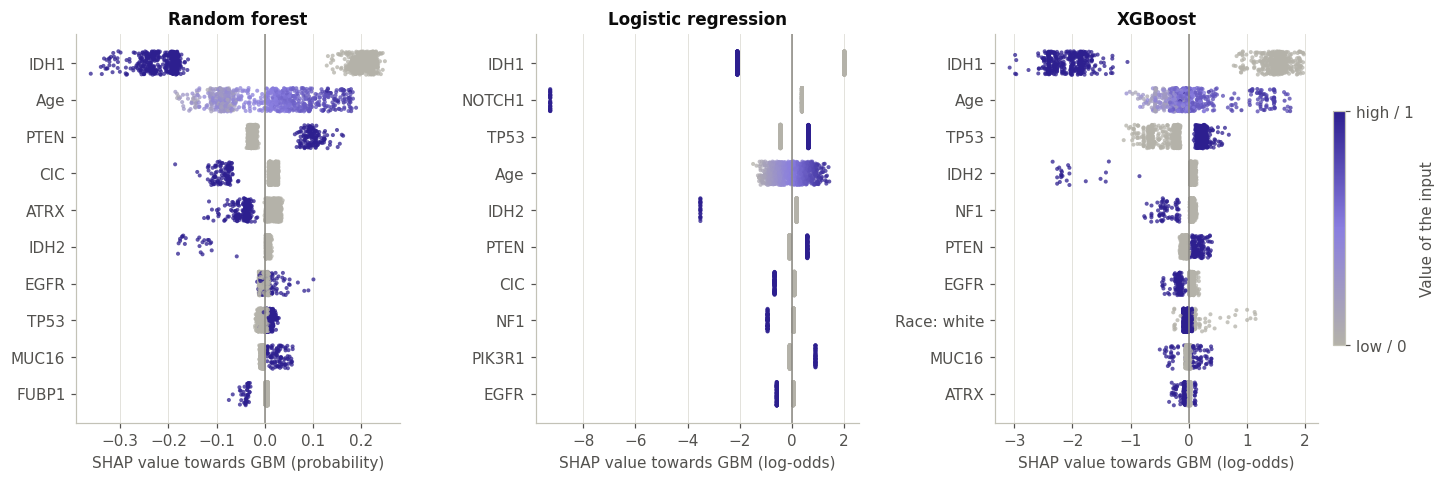

In [4]:
fig, axes = plt.subplots(1, len(WIN_BIN), figsize=(5.4 * len(WIN_BIN), 4.6))
axes = np.atleast_1d(axes)
fig.subplots_adjust(wspace=0.42, left=0.07, right=0.9)
for ax, m in zip(axes, WIN_BIN):
    explain.beeswarm(ax, SV_BIN[m]["values"], SV_BIN[m]["inputs"], top=10, title=m,
                     xlabel=f"SHAP value towards GBM ({SV_BIN[m]['units']})")
sm = plt.cm.ScalarMappable(cmap=explain.VALUE_CMAP); sm.set_array([])
cb = fig.colorbar(sm, ax=axes, shrink=0.6, pad=0.01); cb.set_ticks([0, 1]); cb.set_ticklabels(["low / 0", "high / 1"])
cb.set_label("Value of the input")
plotting.save_figure(fig, "shap_binary_summary")
plt.show()

## 5. Binary task: the effect of age

A SHAP dependence plot shows the contribution of age against age itself. In logistic regression it is a straight line by construction (one coefficient); tree ensembles can learn any shape. Colour: IDH1 status, the strongest predictor, to see whether the effect of age differs between IDH1-mutant and wildtype patients (an interaction that a model without interaction terms cannot represent).

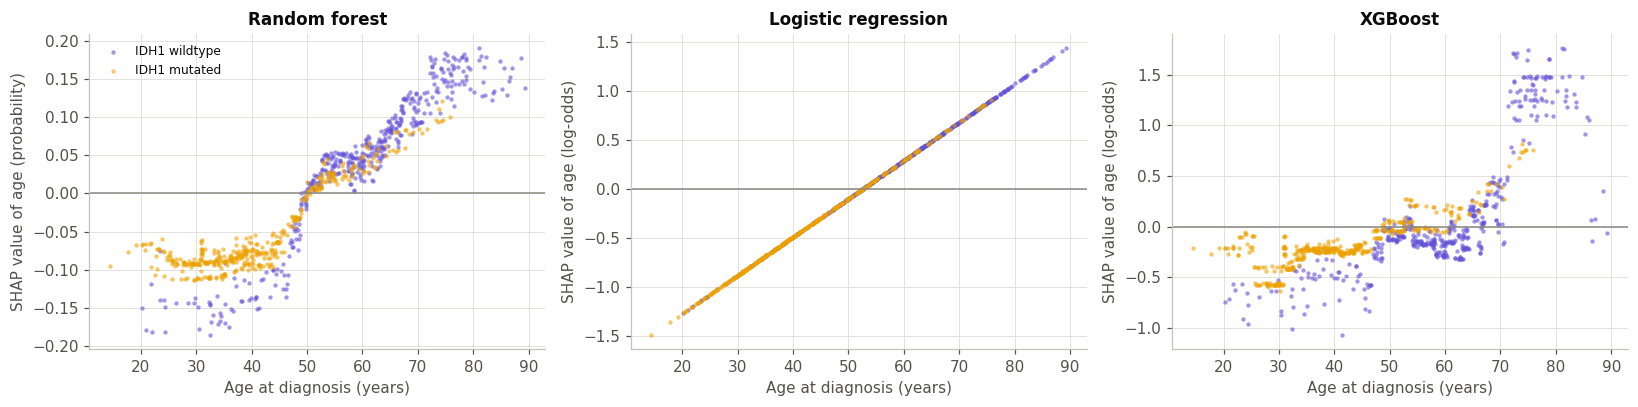

,age where contribution becomes positive,range of the contribution
Random forest,50.04,"[-0.18552729089029585, 0.1901400487873549]"
Logistic regression,52.53,"[-1.487326016969309, 1.4328233231286138]"
XGBoost,52.43,"[-1.0696067810058594, 1.7569546699523926]"


In [5]:
fig, axes = plt.subplots(1, len(WIN_BIN), figsize=(5 * len(WIN_BIN), 3.8), sharex=True)
axes = np.atleast_1d(axes)
age = df["Age_at_diagnosis"].values
idh = df["IDH1"].values
dep = {}
for ax, m in zip(axes, WIN_BIN):
    j = list(SV_BIN[m]["inputs"].columns).index("Age_at_diagnosis")
    v = SV_BIN[m]["values"][:, j]
    for val, colour, lab in ((0, plotting.CATEGORICAL[6], "IDH1 wildtype"), (1, plotting.CATEGORICAL[3], "IDH1 mutated")):
        ax.scatter(age[idh == val], v[idh == val], s=8, alpha=0.6, color=colour, label=lab, linewidths=0)
    ax.axhline(0, color=NEUTRAL, lw=1)
    ax.set_xlabel("Age at diagnosis (years)"); ax.set_ylabel(f"SHAP value of age ({SV_BIN[m]['units']})"); ax.set_title(m)
    # age at which the contribution changes sign (first crossing of a smoothed curve)
    s = pd.Series(v, index=age).sort_index().rolling(51, center=True, min_periods=10).mean()
    cross = s.index[np.flatnonzero(np.diff(np.sign(s.values)) > 0)]
    dep[m] = {"age where contribution becomes positive": float(cross[0]) if len(cross) else None,
              "range of the contribution": [float(v.min()), float(v.max())]}
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plotting.save_figure(fig, "shap_binary_age")
plt.show()
display(pd.DataFrame(dep).T)
results["age_dependence"] = dep

## 6. Multiclass task: what distinguishes each family

For a multiclass model there is one set of SHAP values per class: the contribution of every input to the output of that class. The heatmap shows the mean |SHAP| of the 10 most important inputs for each family (shares within each class, so that each column sums to the same total); the two summary plots show the direction for the two lower-grade families that the clusters of notebook 03 seemed to separate.

Random forest {'max_features': 'sqrt', 'min_samples_leaf': 5} | units: probability | max additivity error: 2.55351295663786e-15


,Astrocytoma,Mixed glioma,Oligodendroglioma,Glioblastoma
IDH1,0.214,0.430,0.322,0.459
Age_at_diagnosis,0.197,0.170,0.046,0.171
CIC,0.124,0.034,0.202,0.074
ATRX,0.126,0.123,0.061,0.064
TP53,0.153,0.018,0.136,0.015
PTEN,0.030,0.071,0.063,0.078
IDH2,0.011,0.016,0.033,0.021
FUBP1,0.022,0.006,0.039,0.015
EGFR,0.020,0.018,0.016,0.016
MUC16,0.014,0.014,0.008,0.016


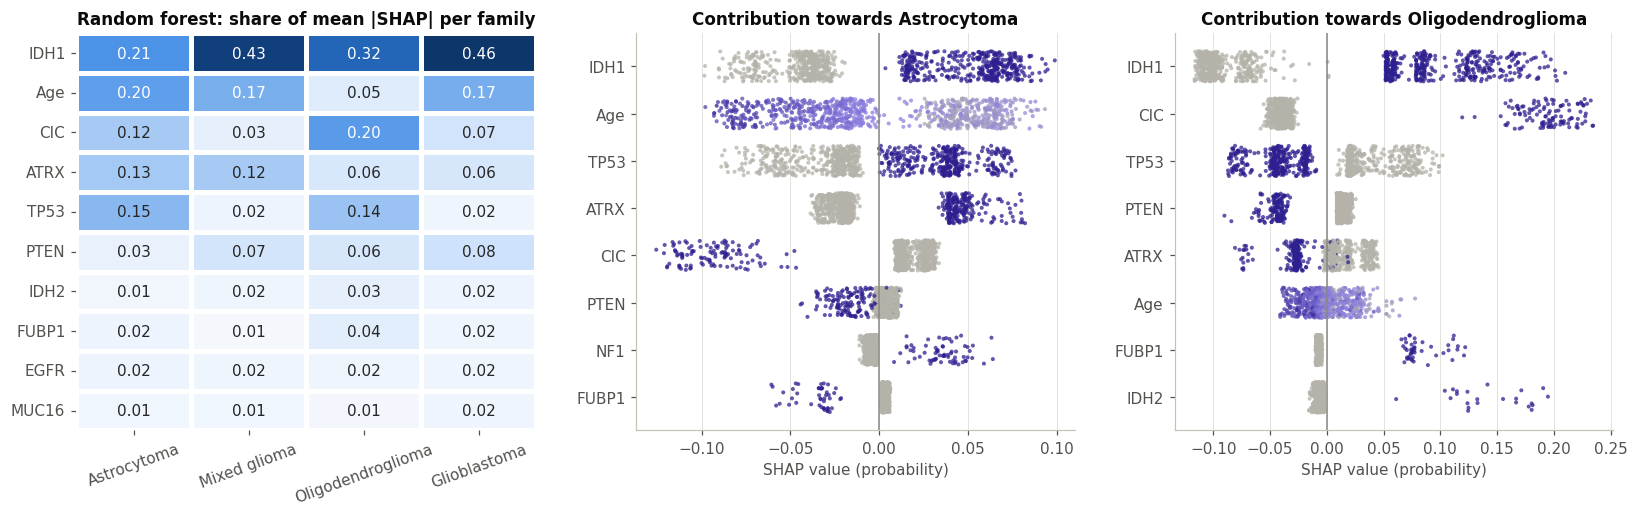

In [6]:
MM = models.multiclass_models(FEATURES)
best_mc = WIN_MC[0]
model_mc, params_mc = ev.fit_final(*MM[best_mc], X, y_mc, "multiclass", ev.MULTICLASS_SCORING)
saved = R06["final_hyperparameters"][best_mc]
assert same_params(params_mc, saved), f"{best_mc}: hyperparameters differ from notebook 06"
SV_MC = explain.shap_values(model_mc, X)
print(best_mc, params_mc, "| units:", SV_MC["units"], "| max additivity error:", explain.additivity_error(SV_MC))
pc = explain.per_class_importance(SV_MC, config.MULTICLASS_LABELS)
pc_share = pc / pc.sum()
top = pc.sum(axis=1).sort_values(ascending=False).index[:10]
display(pc_share.loc[top])
results["multiclass"] = {"model": best_mc, "params": params_mc, "units": SV_MC["units"],
                         "additivity_error": explain.additivity_error(SV_MC),
                         "share_by_class": pc_share.loc[top].to_dict(orient="index"),
                         "top_by_class": {c: pc_share[c].sort_values(ascending=False).index[:3].tolist() for c in pc_share}}
reporting.save_table_tex(pc_share.loc[top].rename_axis("Predictor").reset_index(), "shap_multiclass_share", float_format="{:.3f}")

fig = plt.figure(figsize=(15, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 1, 1])
ax0 = fig.add_subplot(gs[0])
sns.heatmap(pc_share.loc[top].rename(index=explain.SHORT_NAMES), annot=True, fmt=".2f", cmap=plotting.SEQUENTIAL, cbar=False, linewidths=2, linecolor="white", ax=ax0)
ax0.set_title(f"{best_mc}: share of mean |SHAP| per family"); ax0.set_xlabel(""); ax0.tick_params(axis="x", rotation=20)
for i, fam in enumerate(["Astrocytoma", "Oligodendroglioma"]):
    ax = fig.add_subplot(gs[i + 1])
    k = LABELS.index(fam)
    explain.beeswarm(ax, SV_MC["values"][:, :, k], SV_MC["inputs"], top=8, title=f"Contribution towards {fam}",
                     xlabel=f"SHAP value ({SV_MC['units']})")
fig.tight_layout(w_pad=2.5)
plotting.save_figure(fig, "shap_multiclass")
plt.show()

## 7. Summary

Generated from the results above; saved in `results/logs/07_shap.json`.

In [7]:
rows_ = [
    ("Binary winners explained", ", ".join(WIN_BIN)),
    ("Additivity (max error)", ", ".join(f"{r['Model']}: {r['Max additivity error']:.1e}" for _, r in check.iterrows())),
    ("Agreement SHAP vs permutation (Spearman rho)", ", ".join(f"{r['Model']}: {r['Spearman rho (SHAP vs permutation)']:.2f}" for _, r in agree.iterrows())),
    ("Top 3 inputs by SHAP", "; ".join(f"{r['Model']}: {r['Top 3 SHAP']}" for _, r in agree.iterrows())),
    ("Age: contribution becomes positive at", ", ".join(f"{m}: {d['age where contribution becomes positive']:.1f} y" for m, d in dep.items() if d['age where contribution becomes positive'])),
    ("Multiclass model explained", f"{best_mc} ({SV_MC['units']})"),
    ("Top 3 inputs per family", "; ".join(f"{c}: {', '.join(v)}" for c, v in results["multiclass"]["top_by_class"].items())),
]
final_summary = pd.DataFrame(rows_, columns=["Topic", "Finding"])
with pd.option_context("display.max_colwidth", None):
    display(final_summary)
results["findings"] = dict(rows_)
path = reporting.save_json(results, "07_shap")
print("Saved", path.relative_to(config.ROOT))

,Topic,Finding
0,Binary winners explained,"Random forest, Logistic regression, XGBoost"
1,Additivity (max error),"Random forest: 1.3e-15, Logistic regression: 3.6e-15, XGBoost: 1.7e-06"
2,Agreement SHAP vs permutation (Spearman rho),"Random forest: 0.85, Logistic regression: 0.79, XGBoost: 0.68"
3,Top 3 inputs by SHAP,"Random forest: IDH1, Age_at_diagnosis, PTEN; Logistic regression: IDH1, NOTCH1, TP53; XGBoost: IDH1, Age_at_diagnosis, TP53"
4,Age: contribution becomes positive at,"Random forest: 50.0 y, Logistic regression: 52.5 y, XGBoost: 52.4 y"
5,Multiclass model explained,Random forest (probability)
6,Top 3 inputs per family,"Astrocytoma: IDH1, Age_at_diagnosis, TP53; Mixed glioma: IDH1, Age_at_diagnosis, ATRX; Oligodendroglioma: IDH1, CIC, TP53; Glioblastoma: IDH1, Age_at_diagnosis, PTEN"


Saved results\logs\07_shap.json
